In [3]:
# -*- coding: utf-8 -*-
import time
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from skopt import BayesSearchCV
from src.utils import logger as log
from src.config import PROJECT_PATH

# El logger central configura timestamp, nivel, formato y codificación UTF-8.
logger = log.LOGGER
config = log.CONFIG

plt.style.use("ggplot")
rng = np.random.default_rng(123)

PARAMS = {
    "CLASES": ["sano", "deriva", "fallo_duro"],
    "ROLLING_WINDOW": 5,
    "FEATURES": ["ltA_medido", "ltB_medido", "lt_residual", "residual_roll_mean", "residual_slope"],
    "UMBRAL_BASELINE": 0.15,
}


In [4]:
def cargar_y_preparar(path_telemetria: str) -> pd.DataFrame:
    """Carga y prepara los datos de telemetría originales y aumentados.

    Args:
        path_telemetria: Ruta del CSV de telemetría original.

    Returns:
        Telemetría combinada, ordenada y con etiquetas y variables derivadas.

    Raises:
        FileNotFoundError: Si falta alguno de los CSV requeridos.
        OSError: Si no se puede leer alguno de los CSV.
        ValueError: Si los archivos no contienen las columnas necesarias.
        pandas.errors.ParserError: Si un CSV tiene formato inválido.

    Examples:
        >>> datos = cargar_y_preparar('data/raw/telemetria.csv')
        >>> {'label', 'residual_slope'}.issubset(datos.columns)
        True
    """
    # Validar rutas y parámetros antes de leer los archivos.
    path_telemetria = Path(path_telemetria)
    path_telemetria_aumentada = path_telemetria.with_name(
        f"{path_telemetria.stem}_aumentada{path_telemetria.suffix}"
    )
    ventana = PARAMS.get("ROLLING_WINDOW")
    if isinstance(ventana, bool) or not isinstance(ventana, int) or ventana < 1:
        raise ValueError("ROLLING_WINDOW debe ser un entero positivo.")

    # Cargar y combinar los archivos sin duplicar registros equivalentes.
    logger.info("Cargando telemetría desde %s y %s", path_telemetria, path_telemetria_aumentada)
    try:
        tel_original = pd.read_csv(path_telemetria)
        tel_aumentada = pd.read_csv(path_telemetria_aumentada)
    except FileNotFoundError:
        logger.exception("No se encontró uno de los archivos de telemetría requeridos.")
        raise
    except (OSError, pd.errors.ParserError, UnicodeDecodeError):
        logger.exception("No se pudieron interpretar los archivos de telemetría.")
        raise

    columnas_requeridas = {
        "t",
        "lt_residual",
        "sensorA_fallo",
        "sensorB_fallo",
        "sensorA_deriva_activa",
        "sensorB_deriva_activa",
    }
    for nombre, datos in (("original", tel_original), ("aumentada", tel_aumentada)):
        faltantes = columnas_requeridas.difference(datos.columns)
        if faltantes:
            logger.error(
                "Faltan columnas requeridas en telemetría %s: %s", nombre, sorted(faltantes)
            )
            detalle_faltantes = sorted(faltantes)
            raise ValueError(
                f"Faltan columnas requeridas en telemetría {nombre}: {detalle_faltantes}"
            )
    columnas_comunes = tel_original.columns.intersection(tel_aumentada.columns)
    if columnas_comunes.empty:
        raise ValueError("Los archivos de telemetría no comparten columnas para compararlos.")
    tel = pd.concat([tel_original, tel_aumentada], ignore_index=True)
    if tel.empty:
        raise ValueError("Los archivos de telemetría no contienen registros.")
    try:
        tel["t"] = pd.to_numeric(tel["t"], errors="raise")
        tel["lt_residual"] = pd.to_numeric(tel["lt_residual"], errors="raise")
    except (TypeError, ValueError):
        logger.exception("El tiempo o el residual contienen valores no numéricos.")
        raise ValueError("Las columnas 't' y 'lt_residual' deben ser numéricas.") from None
    filas_antes = len(tel)
    tel = tel.drop_duplicates(subset=columnas_comunes)
    logger.debug("Se descartaron %d filas de telemetría duplicadas.", filas_antes - len(tel))

    # Etiquetar cada fila priorizando fallos duros sobre derivas.
    def clase(row):
        """Asigna una clase según las señales de fallo y deriva.

        Args:
            row: Fila de telemetría con indicadores de estado de sensores.

        Returns:
            2 para fallo duro, 1 para deriva o 0 para estado sano.

        Raises:
            KeyError: Si faltan indicadores requeridos en la fila.

        Examples:
            >>> clase(pd.Series({'sensorA_fallo': True, 'sensorB_fallo': False,
            ...                   'sensorA_deriva_activa': False,
            ...                   'sensorB_deriva_activa': False}))
            2
        """
        if row["sensorA_fallo"] or row["sensorB_fallo"]:
            return 2
        if row["sensorA_deriva_activa"] or row["sensorB_deriva_activa"]:
            return 1
        return 0

    # Ordenar cronológicamente y generar las variables derivadas del residual.
    tel = tel.sort_values("t").reset_index(drop=True)
    tel["label"] = tel.apply(clase, axis=1)
    tel["residual_roll_mean"] = tel["lt_residual"].rolling(ventana, min_periods=1).mean()
    tel["residual_slope"] = tel["lt_residual"].diff(ventana).fillna(0) / ventana
    logger.info("Telemetría preparada: %d filas.", len(tel))
    return tel


def dividir_train_test(
    tel: pd.DataFrame, path_episodios: str, n_episodios_prueba: int = 2
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Divide la telemetría cronológicamente usando episodios originales y aumentados.

    Args:
        tel: Telemetría que contiene la columna temporal ``t``.
        path_episodios: Ruta al CSV de episodios original.
        n_episodios_prueba: Cantidad de episodios finales reservados para prueba.

    Returns:
        Tupla con los subconjuntos de entrenamiento y prueba.

    Raises:
        TypeError: Si ``tel`` no es un DataFrame.
        ValueError: Si los datos o el tamaño de prueba no son válidos.
        FileNotFoundError: Si falta alguno de los CSV de episodios.
        OSError: Si no se puede leer alguno de los CSV.
        pandas.errors.ParserError: Si un CSV tiene formato inválido.

    Examples:
        >>> entrenamiento, prueba = dividir_train_test(datos, 'data/raw/episodios.csv')
        >>> len(entrenamiento) + len(prueba) == len(datos)
        True
    """
    # Validar argumentos y derivar la ruta del archivo aumentado.
    if not isinstance(tel, pd.DataFrame):
        raise TypeError("tel debe ser un pandas.DataFrame.")
    if (
        isinstance(n_episodios_prueba, bool)
        or not isinstance(n_episodios_prueba, int)
        or n_episodios_prueba < 1
    ):
        raise ValueError("n_episodios_prueba debe ser un entero positivo.")
    if "t" not in tel.columns or tel.empty:
        raise ValueError("La telemetría debe contener la columna 't' y tener filas.")
    path_episodios = Path(path_episodios)
    path_episodios_aumentados = path_episodios.with_name(
        f"{path_episodios.stem}_aumentados{path_episodios.suffix}"
    )

    # Leer, combinar y quitar duplicados de los episodios.
    try:
        ep_original = pd.read_csv(path_episodios)
        ep_aumentados = pd.read_csv(path_episodios_aumentados)
    except FileNotFoundError:
        logger.exception("No se encontró uno de los archivos de episodios requeridos.")
        raise
    except (OSError, pd.errors.ParserError, UnicodeDecodeError):
        logger.exception("No se pudieron interpretar los archivos de episodios.")
        raise
    columnas_requeridas = {"inicio_t"}
    faltantes = columnas_requeridas.difference(ep_original.columns)
    if faltantes:
        logger.error("Faltan columnas requeridas en episodios: %s", sorted(faltantes))
        detalle_faltantes = sorted(faltantes)
        raise ValueError(f"Faltan columnas requeridas en episodios: {detalle_faltantes}")
    columnas_comunes = ep_original.columns.intersection(ep_aumentados.columns)
    if columnas_comunes.empty:
        raise ValueError("Los archivos de episodios no comparten columnas para compararlos.")
    ep = pd.concat([ep_original, ep_aumentados], ignore_index=True)
    if ep.empty:
        raise ValueError("Los archivos de episodios no contienen registros.")
    filas_antes = len(ep)
    ep = ep.drop_duplicates(subset=columnas_comunes).sort_values("inicio_t")
    logger.debug("Se descartaron %d episodios duplicados.", filas_antes - len(ep))
    if ep.empty or n_episodios_prueba > len(ep):
        raise ValueError("La cantidad de episodios de prueba excede los episodios disponibles.")
    try:
        tiempo_telemetria = pd.to_numeric(tel["t"], errors="raise")
        inicios_episodios = pd.to_numeric(ep["inicio_t"], errors="raise")
    except (TypeError, ValueError):
        logger.exception("Los tiempos de telemetría o episodios contienen valores no numéricos.")
        raise ValueError("Las columnas 't' e 'inicio_t' deben ser numéricas.") from None
    if tiempo_telemetria.isna().any() or inicios_episodios.isna().any():
        raise ValueError("Las columnas temporales no pueden contener valores vacíos.")

    # Establecer el corte temporal y crear subconjuntos disjuntos.
    corte_t = inicios_episodios.iloc[-n_episodios_prueba:].min()
    train = tel[tiempo_telemetria < corte_t]
    test = tel[tiempo_telemetria >= corte_t]
    if train.empty or test.empty:
        logger.warning("La división temporal generó un subconjunto vacío (corte t=%s).", corte_t)
    logger.info(
        "División temporal: %d train | %d test (corte t=%s)", len(train), len(test), corte_t
    )
    return train, test


def graficar_boxplots_cv(busquedas):
    """Grafica la distribución de resultados entre folds de validación cruzada.

    Args:
        busquedas: Diccionario de búsquedas ajustadas con resultados de validación cruzada.

    Returns:
        None.

    Raises:
        TypeError: Si ``busquedas`` no es un diccionario.
        ValueError: Si no hay búsquedas o sus resultados están incompletos.
        OSError: Si no se puede guardar la figura.

    Examples:
        >>> graficar_boxplots_cv(busquedas_ajustadas)
    """
    # Validar las búsquedas y preparar el conjunto de puntuaciones.
    if not isinstance(busquedas, dict):
        raise TypeError("busquedas debe ser un diccionario.")
    if not busquedas:
        raise ValueError("Se requiere al menos una búsqueda para graficar.")
    datos = []
    for nombre, searcher in busquedas.items():
        try:
            cv_res = searcher.cv_results_
            best_idx = searcher.best_index_
            n_splits = searcher.n_splits_
        except AttributeError as error:
            logger.exception("La búsqueda %s no tiene resultados de CV completos.", nombre)
            raise ValueError(f"Resultados de validación cruzada incompletos: {nombre}") from error
        logger.debug("Extrayendo puntuaciones CV para %s.", nombre)
        for i in range(n_splits):
            clave = f"split{i}_test_score"
            if clave not in cv_res or best_idx >= len(cv_res[clave]):
                raise ValueError(f"Falta la puntuación {clave} para la búsqueda {nombre}.")
            datos.append({"Modelo": nombre, "Fold": i, "Accuracy": cv_res[clave][best_idx]})
    if not datos:
        raise ValueError("No se encontraron puntuaciones para construir el gráfico.")
    df_plot = pd.DataFrame(datos)

    # Dibujar el boxplot y guardarlo en la carpeta configurada.
    file_figures = Path(config.paths.reports.figures) / "boxplots_cv.png"
    if not file_figures.exists():
        file_figures = PROJECT_PATH / config.paths.reports.figures / "boxplots_cv.png"
    fig, ax = plt.subplots(figsize=(10, 6))
    try:
        sns.boxplot(x="Modelo", y="Accuracy", data=df_plot, palette="Set2", width=0.5, ax=ax)
        sns.stripplot(
            x="Modelo", y="Accuracy", data=df_plot, color="black", alpha=0.6, jitter=True, ax=ax
        )
        ax.set_title("Estabilidad del mejor modelo en validación cruzada (K-Folds)", fontsize=14)
        ax.set_ylabel("Exactitud en CV")
        ax.set_xlabel("Estrategia de búsqueda")
        fig.tight_layout()
        file_figures.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(file_figures, dpi=150, bbox_inches="tight")
        logger.info("Gráfico de boxplots guardado en %s.", file_figures)
        plt.show()
    except OSError:
        logger.exception("No se pudo guardar el gráfico de boxplots en %s.", file_figures)
        raise
    finally:
        plt.close(fig)


def graficar_coordenadas_paralelas(busquedas):
    """Genera gráficos interactivos de coordenadas paralelas para cada búsqueda.

    Args:
        busquedas: Diccionario de búsquedas ajustadas con hiperparámetros y puntuaciones.

    Returns:
        None.

    Raises:
        TypeError: Si ``busquedas`` no es un diccionario.
        ValueError: Si una búsqueda no contiene resultados graficables.
        OSError: Si no se puede guardar un archivo HTML.

    Examples:
        >>> graficar_coordenadas_paralelas(busquedas_ajustadas)
    """
    # Validar la colección antes de recorrer las búsquedas.
    if not isinstance(busquedas, dict):
        raise TypeError("busquedas debe ser un diccionario.")
    if not busquedas:
        raise ValueError("Se requiere al menos una búsqueda para graficar.")

    # Preparar y guardar un gráfico con los resultados de cada búsqueda.
    for nombre, searcher in busquedas.items():
        try:
            cv_res = searcher.cv_results_
            df_cv = pd.DataFrame(cv_res["params"])
            df_cv["mean_test_score"] = cv_res["mean_test_score"]
        except (AttributeError, KeyError, ValueError) as error:
            logger.exception("No se pudieron obtener resultados graficables para %s.", nombre)
            raise ValueError(f"Resultados incompletos para la búsqueda {nombre}.") from error
        if df_cv.empty or df_cv.shape[1] < 2:
            raise ValueError(f"No hay dimensiones suficientes para graficar la búsqueda {nombre}.")
        if "criterion" in df_cv.columns:
            df_cv["criterion_num"] = df_cv["criterion"].map({"gini": 0, "entropy": 1})
            df_cv = df_cv.drop(columns=["criterion"])
        logger.debug("Generando coordenadas paralelas para %s.", nombre)
        fig = px.parallel_coordinates(
            df_cv,
            color="mean_test_score",
            dimensions=df_cv.columns,
            title=f"Coordenadas paralelas de hiperparámetros - {nombre}",
            color_continuous_scale=px.colors.diverging.Tealrose,
        )
        file_figures = (
            PROJECT_PATH / config.paths.reports.figures / (f"coordenadas_paralelas_{nombre}.html")
        )
        try:
            file_figures.parent.mkdir(parents=True, exist_ok=True)
            fig.write_html(file_figures)
        except OSError:
            logger.exception("No se pudo guardar el gráfico de coordenadas en %s.", file_figures)
            raise
        logger.info("Gráfico de coordenadas paralelas guardado en %s.", file_figures)
        fig.show()


def graficar_matriz_confusion(y_test, y_pred, path_salida):
    """Genera y guarda la matriz de confusión del modelo evaluado.

    Args:
        y_test: Etiquetas verdaderas.
        y_pred: Etiquetas predichas, alineadas con ``y_test``.
        path_salida: Ruta del archivo de imagen de salida.

    Returns:
        None.

    Raises:
        ValueError: Si las etiquetas no tienen igual longitud o están vacías.
        OSError: Si no se puede guardar la imagen.

    Examples:
        >>> graficar_matriz_confusion(etiquetas, predicciones, 'reports/matriz.png')
    """
    # Comprobar los datos antes de calcular la matriz.
    if len(y_test) == 0 or len(y_test) != len(y_pred):
        raise ValueError("y_test e y_pred deben tener la misma longitud no vacía.")
    cm = confusion_matrix(y_test, y_pred, labels=range(len(PARAMS["CLASES"])))
    fig, ax = plt.subplots(figsize=(8, 6))

    # Renderizar y guardar la figura, cerrándola también ante un error.
    try:
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=PARAMS["CLASES"],
            yticklabels=PARAMS["CLASES"],
            linewidths=0.5,
            square=True,
            ax=ax,
        )
        ax.set_title("Matriz de confusión - BayesSearchCV", size=15)
        ax.set_ylabel("Etiqueta real (verdad de terreno)", size=12)
        ax.set_xlabel("Predicción del modelo", size=12)
        fig.tight_layout()
        destino = Path(path_salida)
        destino.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(destino, dpi=150, bbox_inches="tight")
        logger.info("Matriz de confusión guardada en %s.", destino)
    except OSError:
        logger.exception("No se pudo guardar la matriz de confusión en %s.", path_salida)
        raise
    finally:
        plt.close(fig)


def graficar_residual_con_clases(tel: pd.DataFrame, path_salida):
    """Guarda un gráfico del residual en el tiempo, coloreado según su clase.

    Args:
        tel: DataFrame con tiempo, residual y etiqueta de clase.
        path_salida: Ruta del archivo de imagen de salida.

    Returns:
        None.

    Raises:
        TypeError: Si ``tel`` no es un DataFrame.
        ValueError: Si faltan columnas o el conjunto está vacío.
        OSError: Si no se puede guardar la imagen.

    Examples:
        >>> graficar_residual_con_clases(datos, 'reports/residual.png')
    """
    # Validar columnas y preparar colores para las clases conocidas.
    if not isinstance(tel, pd.DataFrame):
        raise TypeError("tel debe ser un pandas.DataFrame.")
    columnas_requeridas = {"t", "lt_residual", "label"}
    faltantes = columnas_requeridas.difference(tel.columns)
    if tel.empty or faltantes:
        raise ValueError(f"La telemetría está vacía o carece de columnas: {
            sorted(faltantes)}")
    colores = {0: "#2ecc71", 1: "#f2a02f", 2: "#e74c3c"}
    fig, ax = plt.subplots(figsize=(9, 4))

    # Dibujar línea base, puntos por clase y umbral de alarma.
    try:
        ax.plot(tel["t"], tel["lt_residual"], color="#333333", linewidth=0.8, zorder=1)
        for clase_id, color in colores.items():
            sub = tel[tel["label"] == clase_id]
            if not sub.empty:
                ax.scatter(
                    sub["t"],
                    sub["lt_residual"],
                    color=color,
                    s=8,
                    label=PARAMS["CLASES"][clase_id],
                    zorder=2,
                )
        ax.axhline(
            PARAMS["UMBRAL_BASELINE"],
            color="#999999",
            linestyle=":",
            linewidth=1,
            label=f"Umbral de alarma ({PARAMS['UMBRAL_BASELINE']} m)",
        )

        # Completar títulos, guardar el archivo y liberar recursos gráficos.
        ax.set_xlabel("Tiempo simulado (s)")
        ax.set_ylabel("Residual |LT-A − LT-B| (m)")
        ax.set_title("Residual de sensores por clase")
        ax.legend(fontsize=8)
        fig.tight_layout()
        destino = Path(path_salida)
        destino.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(destino, dpi=130)
        logger.info("Gráfico de residual guardado en %s.", destino)
    except OSError:
        logger.exception("No se pudo guardar el gráfico de residual en %s.", path_salida)
        raise
    finally:
        plt.close(fig)


In [5]:
def main():
    """Ejecuta el flujo de entrenamiento, evaluación y generación de informes.

    Args:
        Ninguno.

    Returns:
        None.

    Raises:
        FileNotFoundError: Si no se encuentran los archivos de datos requeridos.
        ValueError: Si los datos no permiten entrenar y evaluar los modelos.
        RuntimeError: Si falla el ajuste de uno de los modelos.
        OSError: Si ocurre un error al guardar los informes.

    Examples:
        >>> main()
    """
    # Resolver las rutas de entrada desde la configuración o raíz del proyecto.
    logger.info("Iniciando el flujo de entrenamiento y evaluación.")
    file_path = Path(config.paths.data.raw) / "telemetria.csv"
    if not file_path.exists():
        file_path = PROJECT_PATH / config.paths.data.raw / "telemetria.csv"
    ep_path = Path(config.paths.data.raw) / "episodios.csv"
    if not ep_path.exists():
        ep_path = PROJECT_PATH / config.paths.data.raw / "episodios.csv"

    # Cargar los datos, realizar la partición y comprobar sus dimensiones.
    df_tel = cargar_y_preparar(file_path)
    train, test = dividir_train_test(df_tel, ep_path, n_episodios_prueba=2)
    if train.empty or test.empty:
        logger.error("El conjunto de entrenamiento o prueba está vacío.")
        raise ValueError("No se puede entrenar con una partición vacía.")
    columnas_faltantes = set(PARAMS["FEATURES"]).difference(train.columns)
    if columnas_faltantes:
        raise ValueError(f"Faltan variables predictoras: {
            sorted(columnas_faltantes)}")
    X_train, y_train = train[PARAMS["FEATURES"]], train["label"]
    X_test, y_test = test[PARAMS["FEATURES"]], test["label"]
    logger.debug("Dimensiones train=%s y test=%s.", X_train.shape, X_test.shape)

    # Configurar el estimador y las estrategias de búsqueda de hiperparámetros.
    rf = RandomForestClassifier(random_state=42)
    param_grid = {
        "n_estimators": np.arange(10, 200, 20),
        "max_depth": [10, 20],
        "min_samples_split": [2, 5],
        "min_samples_leaf": [1, 2],
        "criterion": ["gini", "entropy"],
    }
    busquedas = {
        "GridSearchCV": GridSearchCV(rf, param_grid, cv=5, n_jobs=-1, scoring="accuracy"),
        "RandomizedSearchCV": RandomizedSearchCV(
            rf, param_grid, cv=5, n_jobs=-1, scoring="accuracy", n_iter=15, random_state=42
        ),
        "BayesSearchCV": BayesSearchCV(
            rf, param_grid, cv=5, n_jobs=-1, scoring="accuracy", n_iter=20, random_state=42
        ),
    }
    historial_metricas = []

    # Ajustar cada búsqueda, medir desempeño y registrar reportes.
    for nombre, searcher in busquedas.items():
        logger.info("Iniciando búsqueda de hiperparámetros: %s", nombre)
        t0 = time.time()
        try:
            searcher.fit(X_train, y_train)
            best_model = searcher.best_estimator_
            y_pred = best_model.predict(X_test)
        except (ValueError, RuntimeError, OSError):
            logger.exception("Falló el entrenamiento o la predicción del modelo %s.", nombre)
            raise
        t_fit = time.time() - t0
        logger.info("Mejores hiperparámetros encontrados: %s", searcher.best_params_)
        logger.info("Mejor exactitud en validación cruzada: %.2f%%", searcher.best_score_ * 100)

        # Calcular métricas generales y el recall de la clase de fallo duro.
        acc = metrics.accuracy_score(y_test, y_pred)
        total_fallos = (y_test == 2).sum()
        if total_fallos:
            recall_fallo = ((y_pred == 2) & (y_test == 2)).sum() / total_fallos
        else:
            recall_fallo = 0.0
            logger.warning("El conjunto de prueba no contiene ejemplos de fallo duro.")
        logger.info(
            "Tiempo: %.2fs | Exactitud test: %.4f | Recall fallo duro: %.4f",
            t_fit,
            acc,
            recall_fallo,
        )
        historial_metricas.append(
            {
                "Modelo": nombre,
                "Accuracy": acc,
                "Recall (Fallo Duro)": recall_fallo,
                "Tiempo (s)": t_fit,
            }
        )
        reporte = metrics.classification_report(y_test, y_pred, output_dict=True, zero_division=0)
        df_reporte = pd.DataFrame(reporte).transpose().round(3)
        logger.info("Reporte detallado de clasificación:\n%s", df_reporte)

    # Guardar los gráficos comparativos de validación cruzada.
    logger.info("Generando gráficos comparativos de validación cruzada.")
    graficar_boxplots_cv(busquedas)
    graficar_coordenadas_paralelas(busquedas)

    # Generar las figuras del mejor estimador y del residual por clase.
    mejor_modelo = busquedas["BayesSearchCV"].best_estimator_
    y_pred_final = mejor_modelo.predict(X_test)
    ruta_matriz = PROJECT_PATH / config.paths.reports.figures / "matriz_confusion_bayes.png"
    graficar_matriz_confusion(y_test, y_pred_final, path_salida=ruta_matriz)
    ruta_residual = PROJECT_PATH / config.paths.reports.figures / "residual_vs_clases.png"
    graficar_residual_con_clases(df_tel, path_salida=ruta_residual)

    # Presentar el resumen de métricas ordenado por exactitud.
    df_comparacion = pd.DataFrame(historial_metricas).sort_values(by="Accuracy", ascending=False)
    logger.info("Flujo de evaluación completado.")
    print("\nResumen comparativo:")
    print(df_comparacion.to_markdown(index=False))


2026-10-13 20:36:09 [INFO] Cargando telemetría desde: D:\optimization-ai-labs\data\raw\telemetria.csv y D:\optimization-ai-labs\data\raw\telemetria_aumentada.csv
2026-10-13 20:36:09 [INFO] División temporal: 2512 train | 232 test
D:\optimization-ai-labs\.venv\Lib\site-packages\skopt\space\space.py:116: UserWarning: Dimension [10, 20] was inferred to Integer(low=10, high=20, prior='uniform', transform='identity'). In upcoming versions of scikit-optimize, it will be inferred to Categorical(categories=(10, 20), prior=None). See the documentation of the check_dimension function for the upcoming API.
  warnings.warn(
D:\optimization-ai-labs\.venv\Lib\site-packages\skopt\space\space.py:116: UserWarning: Dimension [2, 5] was inferred to Integer(low=2, high=5, prior='uniform', transform='identity'). In upcoming versions of scikit-optimize, it will be inferred to Categorical(categories=(2, 5), prior=None). See the documentation of the check_dimension function for the upcoming API.
  warnings.wa

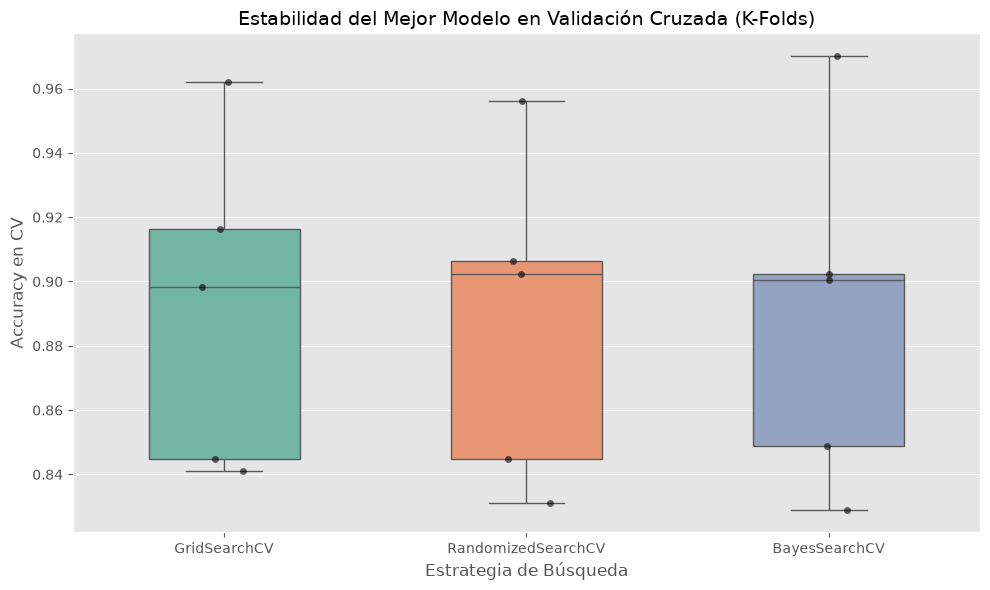

2026-10-13 20:37:29 [INFO] Generando Gráficos de Coordenadas Paralelas...


2026-10-13 20:37:30 [INFO] Generando Matriz de Confusión...
2026-10-13 20:37:31 [INFO] Generando Gráfico Residual vs Clases...



Resumen Comparativo:
| Modelo             |   Accuracy |   Recall (Fallo Duro) |   Tiempo (s) |
|:-------------------|-----------:|----------------------:|-------------:|
| BayesSearchCV      |   0.943966 |              0.166667 |     21.3507  |
| GridSearchCV       |   0.939655 |              0.166667 |     53.3883  |
| RandomizedSearchCV |   0.935345 |              0.166667 |      4.66864 |


In [6]:
main()
